# Project 01: Seed-based Graph Matching with Greedy Percolation

**Goal:** recover the one-to-one mapping between anonymized graph A and auxiliary graph B (B is A with some edges deleted and replaced by random ones), starting from a small set of known seed pairs.

**Method (own implementation, no graph-matching libraries):**
1. Every matched pair `(a, b)` casts one *vote* for each neighbour pair `(x, y)` with `x in N(a)`, `y in N(b)`. `M[u, v]` counts the votes for `(u, v)`.
2. Greedily match the pair with the highest priority that has at least `r` votes (random pairs rarely collect `r` votes), then add votes for the new pair's neighbours. The matching spreads from the seeds (*percolation*).
3. Optional rejection rule (margin over the runner-up) and a final leftover assignment with `scipy.optimize.linear_sum_assignment`.

**Protocol:** tune only on Train, confirm on Val, freeze the configuration in `config.json`, then predict Test. Test truth is never read.

**Notebook map:** 1 Setup and data loading, 2 Metrics, 3 Baselines, 4 Percolation, 5 Tuning on Train, 6 Validation and freeze, 7 Full experiments, 8 Confidence, 9 Test predictions, 10 Results summary.

## 1. Setup and data loading
Graphs are stored as symmetric 0/1 sparse CSR matrices; seeds and truth are `{node_a: node_b}` dicts.

In [1]:
import json
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from scipy.optimize import linear_sum_assignment

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
DATA = Path('student/seed_based')
RESULTS = Path('results'); RESULTS.mkdir(exist_ok=True)
(RESULTS / 'figs').mkdir(exist_ok=True)
rng_note = 'Everything below is deterministic (no random numbers are drawn).'

In [2]:
def build_adj(edges, n):
    """Symmetric 0/1 CSR adjacency without self-loops or duplicate edges."""
    m = sp.coo_matrix((np.ones(len(edges)), (edges.source, edges.target)), shape=(n, n))
    m = (m + m.T).tocsr()
    m.setdiag(0)
    m.eliminate_zeros()
    m.data[:] = 1.0
    return m


def load_instance(split, name, seed_kind="random", seed_pct=5):
    d = DATA / split / name
    n_a = len(pd.read_csv(d / "nodes_a.csv"))
    n_b = len(pd.read_csv(d / "nodes_b.csv"))
    A = build_adj(pd.read_csv(d / "edges_a.csv"), n_a)
    B = build_adj(pd.read_csv(d / "edges_b.csv"), n_b)
    seeds = pd.read_csv(d / f"seeds_{seed_kind}_{seed_pct:02d}.csv")
    seeds = dict(zip(seeds.node_a, seeds.node_b))
    gt = d / "ground_truth.csv"
    truth = None
    if gt.exists():
        t = pd.read_csv(gt)
        truth = dict(zip(t.node_a, t.node_b))
    meta = json.loads((d / "metadata.json").read_text())
    return A, B, seeds, truth, meta


In [3]:
# Check the loader on one instance
A, B, seeds, truth, meta = load_instance('val', 'erdos_renyi_hard_00', 'random', 5)
print(meta['family'], meta['difficulty'], 'n =', A.shape[0], '| edges A/B =', A.nnz // 2, B.nnz // 2, '| seeds =', len(seeds))
assert (A != A.T).nnz == 0 and A.diagonal().sum() == 0
assert all(truth[a] == b for a, b in seeds.items()), 'seeds must agree with ground truth'
print('mean degree A/B:', A.sum(1).mean().round(1), B.sum(1).mean().round(1))

erdos_renyi hard n = 1000 | edges A/B = 29788 29788 | seeds = 50
mean degree A/B: 59.6 59.6


## 2. Metrics
Precision = correct / predicted, recall = correct / n, F1, coverage = predicted / n. Because seeds are given for free, every metric is also reported on **unseeded** nodes only (seed pairs removed from prediction and truth). Metrics are computed per graph instance and then averaged over instances (never pooled over nodes).

In [4]:
def evaluate(pred, truth, seeds, n):
    """Precision / recall / F1 / coverage, overall and on unseeded nodes only."""
    correct = sum(truth.get(a) == b for a, b in pred.items())
    p = correct / len(pred) if pred else 0.0
    r = correct / n
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    un_pred = {a: b for a, b in pred.items() if a not in seeds}
    un_truth_n = n - len(seeds)
    un_correct = sum(truth.get(a) == b for a, b in un_pred.items())
    un_p = un_correct / len(un_pred) if un_pred else 0.0
    un_r = un_correct / un_truth_n if un_truth_n else 0.0
    un_f1 = 2 * un_p * un_r / (un_p + un_r) if un_p + un_r else 0.0
    return dict(
        precision=p, recall=r, f1=f1, coverage=len(pred) / n,
        unseeded_precision=un_p, unseeded_recall=un_r, unseeded_f1=un_f1,
        unseeded_coverage=len(un_pred) / un_truth_n if un_truth_n else 0.0,
    )


In [5]:
# Sanity checks: perfect prediction -> 1.0 everywhere; seeds only -> unseeded recall 0
n = A.shape[0]
print({k: round(v, 3) for k, v in evaluate(dict(truth), truth, seeds, n).items()})
print({k: round(v, 3) for k, v in evaluate(dict(seeds), truth, seeds, n).items()})

{'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'coverage': 1.0, 'unseeded_precision': 1.0, 'unseeded_recall': 1.0, 'unseeded_f1': 1.0, 'unseeded_coverage': 1.0}
{'precision': 1.0, 'recall': 0.05, 'f1': 0.095, 'coverage': 0.05, 'unseeded_precision': 0.0, 'unseeded_recall': 0.0, 'unseeded_f1': 0.0, 'unseeded_coverage': 0.0}


## 3. Baselines
Seeds only (insufficient by the task rules) and a degree-rank matching (a weak structural floor).

In [6]:
def degree_rank_baseline(A, B, seeds):
    """Pair unseeded nodes by degree rank (a deliberately weak floor)."""
    da = np.asarray(A.sum(1)).ravel()
    db = np.asarray(B.sum(1)).ravel()
    ua = [u for u in np.argsort(-da, kind="stable") if u not in seeds]
    used_b = set(seeds.values())
    ub = [v for v in np.argsort(-db, kind="stable") if v not in used_b]
    pred = dict(seeds)
    pred.update(zip(ua, ub))
    return pred


## 4. Greedy percolation
`M = A @ P @ B.T` (with `P` the seed indicator matrix) gives the initial vote counts in one sparse product. The loop then repeatedly:
- takes the highest-priority unmatched pair with `M >= r` (priority = votes, optionally degree-normalised, ties broken by degree similarity),
- optionally rejects it unless it beats the runner-up in its row and column by `margin` votes (rejected pairs are only reconsidered if their vote count grows),
- matches it and adds a vote to every neighbour pair `N_A(u) x N_B(v)`.

Options: `r` (vote threshold), `margin`, `norm='deg'` (divide votes by `sqrt(deg_a * deg_b)`, rescaled to vote units; helps against hubs), `r_final` (leftover stage: Hungarian assignment on the remaining unmatched nodes, keeping pairs with at least `r_final` votes).

In [7]:
def percolate(A, B, seeds, r=2, margin=0, norm="none", r_final=None):
    """Greedy percolation graph matching.

    M[u, v] = number of already-matched neighbour pairs supporting (u, v).
    Repeatedly match the best-priority pair with M >= r (and a margin over the
    runner-up in its row/column), then add votes for the new pair's neighbours.
    Returns (pred, info) where info logs score/margin/order of every match.
    """
    n = A.shape[0]
    P = sp.csr_matrix(
        (np.ones(len(seeds)), (list(seeds.keys()), list(seeds.values()))), shape=(n, n)
    )
    Mraw = (A @ P @ B.T).toarray().astype(np.float32)
    dA = np.asarray(A.sum(1)).ravel()
    dB = np.asarray(B.sum(1)).ravel()
    scale = np.ones((n, n), np.float32)
    if norm == "deg":
        scale = (1.0 / np.sqrt(np.outer(np.maximum(dA, 1), np.maximum(dB, 1)))).astype(np.float32)
        scale *= np.sqrt(np.maximum(dA.mean(), 1) * np.maximum(dB.mean(), 1))
    # tie-break strictly below one vote: prefer pairs with similar degree
    tb = (-np.abs(dA[:, None] - dB[None, :]) / (max(dA.max(), dB.max()) + 1) * 0.5).astype(np.float32)
    used_a = np.zeros(n, bool)
    used_b = np.zeros(n, bool)
    dscore = np.full((n, n), -1.0, np.float32)  # score at which a pair was rejected
    pred = dict(seeds)
    for a, b in seeds.items():
        used_a[a] = used_b[b] = True
    log = []

    def priority(rows, cols):
        sub = Mraw[np.ix_(rows, cols)]
        ok = (sub >= r) & (sub > dscore[np.ix_(rows, cols)])
        ok &= ~used_a[rows][:, None] & ~used_b[cols][None, :]
        return np.where(ok, sub * scale[np.ix_(rows, cols)] + tb[np.ix_(rows, cols)], -np.inf)

    allr, allc = np.arange(n), np.arange(n)
    Q = priority(allr, allc)
    nbrs_a = lambda u: A.indices[A.indptr[u]:A.indptr[u + 1]]
    nbrs_b = lambda v: B.indices[B.indptr[v]:B.indptr[v + 1]]
    while True:
        k = int(Q.argmax())
        u, v = divmod(k, n)
        if Q[u, v] == -np.inf:
            break
        s = float(Mraw[u, v])
        gap = np.nan
        if margin > 0:
            row = Mraw[u].copy(); row[used_b] = -1; row[v] = -1
            col = Mraw[:, v].copy(); col[used_a] = -1; col[u] = -1
            gap = s - max(row.max(), col.max())
            if gap < margin:
                dscore[u, v] = s
                Q[u, v] = -np.inf
                continue
        pred[u] = v
        used_a[u] = used_b[v] = True
        Q[u, :] = -np.inf
        Q[:, v] = -np.inf
        log.append((u, v, s, gap))
        ra, cb = nbrs_a(u), nbrs_b(v)
        if len(ra) and len(cb):
            Mraw[np.ix_(ra, cb)] += 1
            Q[np.ix_(ra, cb)] = priority(ra, cb)

    n_perc = len(pred)
    if r_final is not None:
        ua = np.where(~used_a)[0]
        ub = np.where(~used_b)[0]
        if len(ua) and len(ub):
            sub = Mraw[np.ix_(ua, ub)]
            ri, ci = linear_sum_assignment(-sub)
            for i, j in zip(ri, ci):
                if sub[i, j] >= r_final:
                    pred[int(ua[i])] = int(ub[j])
                    log.append((int(ua[i]), int(ub[j]), float(sub[i, j]), np.nan))
    info = pd.DataFrame(log, columns=["node_a", "node_b", "score", "gap"])
    info["stage"] = ["perc"] * (n_perc - len(seeds)) + ["final"] * (len(info) - (n_perc - len(seeds)))
    return pred, info


In [8]:
# Demo on one instance: the baselines vs percolation (5% random seeds)
t = time.perf_counter(); pred, info = percolate(A, B, seeds, r=2); dt = time.perf_counter() - t
demo = pd.DataFrame({
    'seeds only': evaluate(dict(seeds), truth, seeds, n),
    'degree rank': evaluate(degree_rank_baseline(A, B, seeds), truth, seeds, n),
    'percolation r=2': evaluate(pred, truth, seeds, n),
}).T[['precision', 'recall', 'f1', 'coverage', 'unseeded_precision', 'unseeded_recall']]
display(demo.round(3)); print(f'percolation runtime: {dt:.2f}s, matches added: {len(info)}')

,precision,recall,f1,coverage,unseeded_precision,unseeded_recall
seeds only,1.000,0.050,0.095,0.05,0.000,0.000
degree rank,0.052,0.052,0.052,1.00,0.002,0.002
percolation r=2,1.000,1.000,1.000,1.00,1.000,1.000


percolation runtime: 0.46s, matches added: 950


## 5. Tuning on Train only
Helpers to run a configuration over many instances (in parallel) and collect per-instance metrics + runtime. The grid is scored by **mean unseeded F1 over Train instances** at 1% and 5% seeds (random and degree), so configurations must work in the hard low-seed regime too.

In [9]:
def list_instances(split):
    return sorted(p.name for p in (DATA / split).iterdir() if p.is_dir())


def run_one(split, name, kind, pct, cfg, method="perc"):
    """One (instance, seed setting, config) run -> metrics row incl. runtime."""
    A, B, seeds, truth, meta = load_instance(split, name, kind, pct)
    n = A.shape[0]
    t = time.perf_counter()
    if method == "perc":
        pred, _ = percolate(A, B, seeds, **cfg)
    elif method == "degree_rank":
        pred = degree_rank_baseline(A, B, seeds)
    else:  # seeds only
        pred = dict(seeds)
    dt = time.perf_counter() - t
    row = evaluate(pred, truth, seeds, n)
    row.update(split=split, instance=name, family=meta["family"], difficulty=meta["difficulty"], n=n,
               seed_kind=kind, seed_pct=pct, runtime=dt, method=method, cfg=json.dumps(cfg, sort_keys=True))
    return row


def run_grid(split, settings, cfgs, method="perc"):
    jobs = [(split, nm, k, p, c) for nm in list_instances(split) for (k, p) in settings for c in cfgs]
    rows = Parallel(n_jobs=-1)(delayed(run_one)(*j, method=method) for j in jobs)
    return pd.DataFrame(rows)


print({s: len(list_instances(s)) for s in ['train', 'val', 'test']})

{'train': 27, 'val': 9, 'test': 18}


In [10]:
# Stage 1: threshold r x margin x normalisation (no leftover stage yet)
TUNE_SETTINGS = [("random", 1), ("degree", 1), ("random", 5), ("degree", 5)]
grid1 = [dict(r=r, margin=m, norm=nm) for r in (1, 2, 3) for m in (0, 1) for nm in ("none", "deg")]
t0 = time.perf_counter()
tune1 = run_grid("train", TUNE_SETTINGS, grid1)
print(f"stage 1 took {time.perf_counter() - t0:.0f}s")
s1 = (tune1.groupby("cfg")[["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage", "runtime"]].mean()
      .sort_values("unseeded_f1", ascending=False))
display(s1.round(3))
best1 = json.loads(s1.index[0]); print("best stage-1 config:", best1)

stage 1 took 32s


,unseeded_precision,unseeded_recall,unseeded_f1,coverage,runtime
cfg,,,,,
"{""margin"": 0, ""norm"": ""none"", ""r"": 1}",0.966,0.966,0.966,1.000,0.270
"{""margin"": 0, ""norm"": ""none"", ""r"": 2}",0.958,0.948,0.948,0.969,0.263
"{""margin"": 0, ""norm"": ""deg"", ""r"": 2}",0.921,0.908,0.910,0.964,0.264
"{""margin"": 0, ""norm"": ""deg"", ""r"": 1}",0.876,0.876,0.876,0.999,0.268
"{""margin"": 1, ""norm"": ""none"", ""r"": 1}",0.838,0.787,0.787,0.789,0.474
"{""margin"": 1, ""norm"": ""none"", ""r"": 2}",0.838,0.787,0.787,0.789,0.263
"{""margin"": 1, ""norm"": ""deg"", ""r"": 1}",0.837,0.785,0.786,0.788,0.776
"{""margin"": 1, ""norm"": ""deg"", ""r"": 2}",0.837,0.785,0.786,0.788,0.304
"{""margin"": 0, ""norm"": ""none"", ""r"": 3}",0.785,0.763,0.764,0.779,0.245


best stage-1 config: {'margin': 0, 'norm': 'none', 'r': 1}


In [11]:
# Stage 2: leftover Hungarian stage on top of the best stage-1 config
grid2 = [dict(best1, r_final=rf) for rf in (None, 1, 2, 3)]
tune2 = run_grid("train", TUNE_SETTINGS, grid2)
s2 = (tune2.groupby("cfg")[["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage", "runtime"]].mean()
      .sort_values("unseeded_f1", ascending=False))
display(s2.round(3))
best_cfg = json.loads(s2.index[0]); print("best Train config:", best_cfg)

,unseeded_precision,unseeded_recall,unseeded_f1,coverage,runtime
cfg,,,,,
"{""margin"": 0, ""norm"": ""none"", ""r"": 1, ""r_final"": 1}",0.966,0.966,0.966,1.0,0.269
"{""margin"": 0, ""norm"": ""none"", ""r"": 1, ""r_final"": 2}",0.966,0.966,0.966,1.0,0.271
"{""margin"": 0, ""norm"": ""none"", ""r"": 1, ""r_final"": 3}",0.966,0.966,0.966,1.0,0.272
"{""margin"": 0, ""norm"": ""none"", ""r"": 1, ""r_final"": null}",0.966,0.966,0.966,1.0,0.278


best Train config: {'margin': 0, 'norm': 'none', 'r': 1, 'r_final': 1}


## 6. Confirm on Val and freeze
Val is used once, to confirm the Train-chosen configuration generalises (and to compare against the default `r=2`). The configuration is then written to `config.json` and **not changed again**.

In [12]:
val_cmp = run_grid("val", TUNE_SETTINGS, [dict(r=2), best_cfg])
cmp_tbl = (val_cmp.groupby(["cfg", "seed_kind", "seed_pct"])[["unseeded_precision", "unseeded_recall", "unseeded_f1", "coverage"]]
           .mean().round(3))
display(cmp_tbl)
tr = tune2[tune2.cfg == json.dumps(best_cfg, sort_keys=True)].unseeded_f1.mean()
va = val_cmp[val_cmp.cfg == json.dumps(best_cfg, sort_keys=True)].unseeded_f1.mean()
print(f"mean unseeded F1 of chosen config: Train {tr:.3f} | Val {va:.3f}")

unseeded_precision  unseeded_recall  unseeded_f1  coverage
cfg                                                seed_kind seed_pct                                                            
{"margin": 0, "norm": "none", "r": 1, "r_final"... degree    1                      0.993            0.993        0.993     1.000
                                                             5                      1.000            1.000        1.000     1.000
                                                   random    1                      0.982            0.982        0.982     1.000
                                                             5                      1.000            1.000        1.000     1.000
{"r": 2}                                           degree    1                      0.993            0.993        0.993     0.999
                                                             5                      1.000            0.999        1.000     1.000
                                                   random    1                      0.983            0.982        0.982     0.999
                                                             5                      1.000            0.999        1.000     1.000

mean unseeded F1 of chosen config: Train 0.966 | Val 0.994


In [13]:
FROZEN = dict(method="greedy percolation", percolate_params=best_cfg,
              submission_seeds=dict(kind="random", pct=5),
              note="Chosen on Train (mean unseeded F1 at 1%/5% seeds, random+degree); confirmed on Val; frozen before Test.")
Path("config.json").write_text(json.dumps(FROZEN, indent=2))
print(Path("config.json").read_text())

{
  "method": "greedy percolation",
  "percolate_params": {
    "margin": 0,
    "norm": "none",
    "r": 1,
    "r_final": 1
  },
  "submission_seeds": {
    "kind": "random",
    "pct": 5
  },
  "note": "Chosen on Train (mean unseeded F1 at 1%/5% seeds, random+degree); confirmed on Val; frozen before Test."
}


## 7. Full experiments (frozen config): Train + Val, all seed strategies and levels
Headline comparison is 5%. Each row below is one graph instance; tables average over instances.

In [14]:
ALL_SETTINGS = [(k, p) for k in ("random", "degree") for p in (1, 5, 10)]
cfg = FROZEN["percolate_params"]
frames = []
for split in ("train", "val"):
    frames.append(run_grid(split, ALL_SETTINGS, [cfg]))
    frames.append(run_grid(split, [("random", 5)], [{}], method="degree_rank"))
    frames.append(run_grid(split, [("random", 5)], [{}], method="seeds_only"))
res = pd.concat(frames, ignore_index=True)
for split in ("train", "val"):
    res[res.split == split].to_csv(RESULTS / f"{split}_results.csv", index=False)
perc = res[res.method == "perc"]
print(len(res), "runs saved to results/")

288 runs saved to results/


In [15]:
metrics = ["precision", "recall", "f1", "coverage", "unseeded_precision", "unseeded_recall", "unseeded_f1"]
head = perc[perc.seed_pct == 5].groupby(["split", "seed_kind"])[metrics].mean().round(3)
display(Markdown("**Headline: 5% seeds, mean over instances**")); display(head)
bl = res[(res.seed_pct == 5) & ((res.method != "perc") | (res.seed_kind == "random"))]
bl = bl.assign(method=bl.method.replace({"perc": "percolation (frozen)", "degree_rank": "degree-rank", "seeds_only": "seeds only"}))
display(Markdown("**Baselines vs percolation (5% random seeds, mean over instances)**"))
display(bl.groupby(["split", "method"])[["precision", "recall", "unseeded_recall"]].mean().round(3))

**Headline: 5% seeds, mean over instances**

precision  recall   f1  coverage  unseeded_precision  unseeded_recall  unseeded_f1
split seed_kind                                                                                    
train degree           1.0     1.0  1.0       1.0                 1.0              1.0          1.0
      random           1.0     1.0  1.0       1.0                 1.0              1.0          1.0
val   degree           1.0     1.0  1.0       1.0                 1.0              1.0          1.0
      random           1.0     1.0  1.0       1.0                 1.0              1.0          1.0

**Baselines vs percolation (5% random seeds, mean over instances)**

precision  recall  unseeded_recall
split method                                                  
train degree-rank               0.068   0.068            0.019
      percolation (frozen)      1.000   1.000            1.000
      seeds only                1.000   0.050            0.000
val   degree-rank               0.065   0.065            0.016
      percolation (frozen)      1.000   1.000            1.000
      seeds only                1.000   0.050            0.000

In [16]:
display(Markdown("**Unseeded recall by family and difficulty (Val, 5%)**"))
v5 = perc[(perc.split == "val") & (perc.seed_pct == 5)]
display(v5.pivot_table(index=["family", "difficulty"], columns="seed_kind", values="unseeded_recall").round(3))
display(Markdown("**Unseeded recall by seed level (Train+Val, mean over instances)**"))
lvl = perc.pivot_table(index=["family", "seed_kind"], columns="seed_pct", values="unseeded_recall").round(3)
display(lvl)
display(Markdown("**Runtime (seconds per instance) by graph size**"))
display(perc.groupby("n").runtime.agg(["mean", "max"]).round(2))

**Unseeded recall by family and difficulty (Val, 5%)**

seed_kind                           degree  random
family                  difficulty                
erdos_renyi             easy         1.000   1.000
                        hard         1.000   1.000
                        medium       1.000   1.000
preferential_attachment easy         1.000   1.000
                        hard         0.998   0.998
                        medium       1.000   1.000
stochastic_block        easy         1.000   1.000
                        hard         1.000   1.000
                        medium       1.000   1.000

**Unseeded recall by seed level (Train+Val, mean over instances)**

seed_pct                              1      5    10
family                  seed_kind                   
erdos_renyi             degree     0.987  1.000  1.0
                        random     0.993  1.000  1.0
preferential_attachment degree     0.995  1.000  1.0
                        random     0.837  1.000  1.0
stochastic_block        degree     0.955  0.999  1.0
                        random     0.909  1.000  1.0

**Runtime (seconds per instance) by graph size**

,mean,max
n,,
300,0.02,0.04
600,0.14,0.18
1000,0.57,0.71


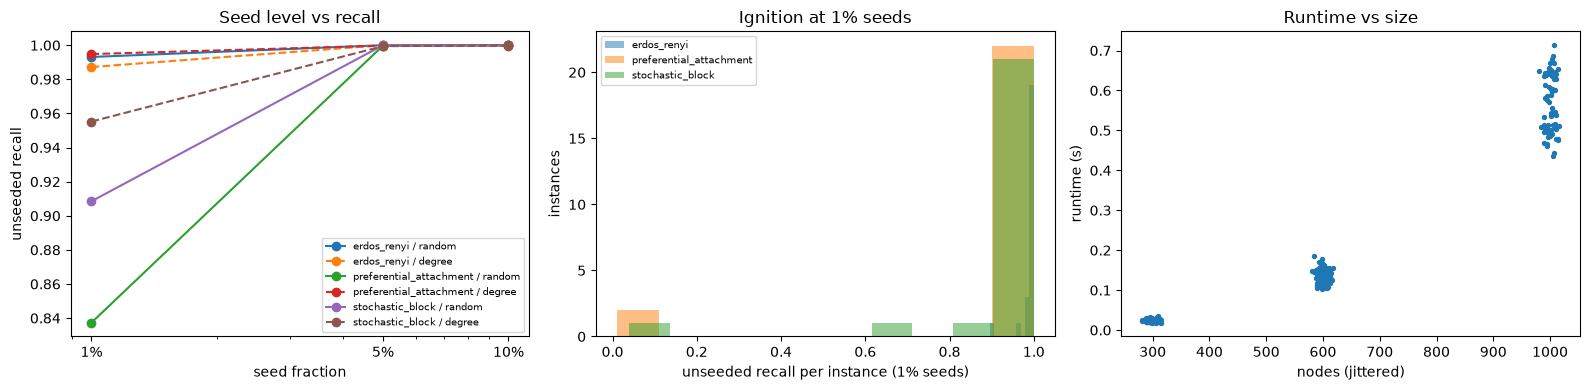

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for fam, g in perc.groupby("family"):
    for kind, ls in (("random", "-"), ("degree", "--")):
        gg = g[g.seed_kind == kind].groupby("seed_pct").unseeded_recall.mean()
        ax[0].plot(gg.index, gg.values, ls, marker="o", label=f"{fam} / {kind}")
ax[0].set_xscale("log"); ax[0].set_xticks([1, 5, 10]); ax[0].set_xticklabels(["1%", "5%", "10%"])
ax[0].set_xlabel("seed fraction"); ax[0].set_ylabel("unseeded recall"); ax[0].set_title("Seed level vs recall"); ax[0].legend(fontsize=7)
d1 = perc[perc.seed_pct == 1]
for fam, g in d1.groupby("family"):
    ax[1].hist(g.unseeded_recall, bins=10, alpha=0.5, label=fam)
ax[1].set_xlabel("unseeded recall per instance (1% seeds)"); ax[1].set_ylabel("instances"); ax[1].set_title("Ignition at 1% seeds"); ax[1].legend(fontsize=7)
ax[2].scatter(perc.n + np.random.default_rng(0).normal(0, 8, len(perc)), perc.runtime, s=8)
ax[2].set_xlabel("nodes (jittered)"); ax[2].set_ylabel("runtime (s)"); ax[2].set_title("Runtime vs size")
plt.tight_layout(); plt.savefig(RESULTS / "figs" / "experiments.png", dpi=130); plt.show()

## 8. Matching confidence
Percolation logs the vote count (and, when `margin > 0`, the gap to the runner-up) of every match. If these are informative, uncertain matches could be omitted to trade coverage for precision (the task allows omitting uncertain nodes).

**Match accuracy vs vote count (Val, 1% seeds, all matches made)**

,accuracy,matches
score_bin,,
"(0, 1]",0.750,12
"(1, 2]",0.707,75
"(2, 3]",0.930,273
"(3, 4]",0.977,1245
"(4, 6]",0.994,2860
"(6, 10]",0.992,1233
"(10, 1000]",1.000,5587


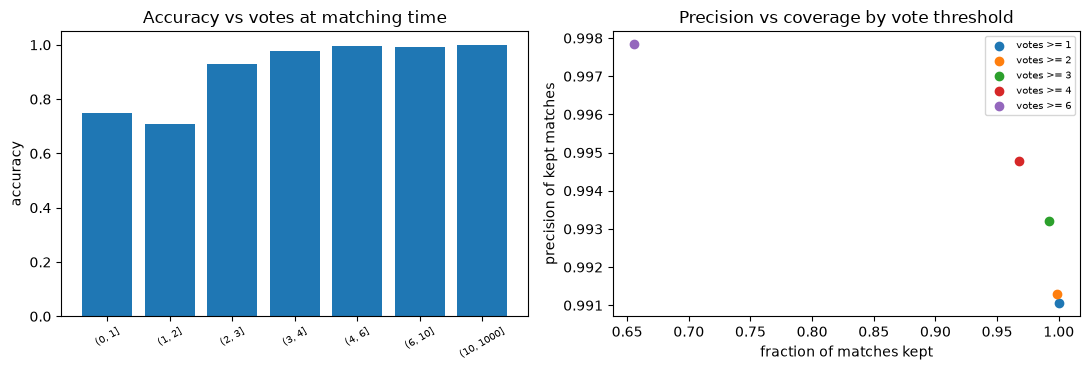

In [18]:
conf = []
for name in list_instances("val"):
    for kind in ("random", "degree"):
        A_, B_, s_, tr_, mt_ = load_instance("val", name, kind, 1)
        p_, inf_ = percolate(A_, B_, s_, **cfg)
        inf_["correct"] = [tr_[a] == b for a, b in zip(inf_.node_a, inf_.node_b)]
        inf_["order"] = np.arange(len(inf_)) / max(len(inf_), 1)
        inf_["family"] = mt_["family"]; inf_["instance"] = name; inf_["kind"] = kind
        conf.append(inf_)
conf = pd.concat(conf, ignore_index=True)
conf["score_bin"] = pd.cut(conf.score, [0, 1, 2, 3, 4, 6, 10, 1000], right=True)
tbl = conf.groupby("score_bin", observed=True).correct.agg(["mean", "size"]).rename(columns={"mean": "accuracy", "size": "matches"})
display(Markdown("**Match accuracy vs vote count (Val, 1% seeds, all matches made)**")); display(tbl.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].bar(range(len(tbl)), tbl.accuracy); ax[0].set_xticks(range(len(tbl))); ax[0].set_xticklabels([str(i) for i in tbl.index], rotation=30, fontsize=7)
ax[0].set_ylabel("accuracy"); ax[0].set_title("Accuracy vs votes at matching time")
for thr in (1, 2, 3, 4, 6):
    k = conf[conf.score >= thr]
    ax[1].scatter(len(k) / len(conf), k.correct.mean(), label=f"votes >= {thr}")
ax[1].set_xlabel("fraction of matches kept"); ax[1].set_ylabel("precision of kept matches"); ax[1].legend(fontsize=7); ax[1].set_title("Precision vs coverage by vote threshold")
plt.tight_layout(); plt.savefig(RESULTS / "figs" / "confidence.png", dpi=130); plt.show()

## 9. Test predictions (frozen config)
The frozen configuration is read back from `config.json`; test truth does not exist locally and is never accessed. Seeds are part of the submitted mapping.

In [19]:
frozen = json.loads(Path("config.json").read_text())
sk, sp_ = frozen["submission_seeds"]["kind"], frozen["submission_seeds"]["pct"]
OUT = Path("predictions")
summary = []
for name in list_instances("test"):
    A_, B_, s_, _, mt_ = load_instance("test", name, sk, sp_)
    t = time.perf_counter()
    p_, inf_ = percolate(A_, B_, s_, **frozen["percolate_params"])
    dt = time.perf_counter() - t
    out = pd.DataFrame(sorted(p_.items()), columns=["node_a", "node_b"])
    # validity checks
    n_ = A_.shape[0]
    assert out.node_a.is_unique and out.node_b.is_unique, name
    assert out.node_a.between(0, n_ - 1).all() and out.node_b.between(0, B_.shape[0] - 1).all(), name
    assert all(p_[a] == b for a, b in s_.items()), name
    (OUT / name).mkdir(parents=True, exist_ok=True)
    out.to_csv(OUT / name / "predictions.csv", index=False)
    summary.append(dict(instance=name, family=mt_["family"], difficulty=mt_["difficulty"], n=n_, seeds=len(s_),
                        predicted=len(out), coverage=len(out) / n_, runtime=dt))
test_summary = pd.DataFrame(summary)
display(test_summary.round(3)); print("wrote", len(summary), "prediction files; all validity checks passed")

,instance,family,difficulty,n,seeds,predicted,coverage,runtime
0,erdos_renyi_easy_00,erdos_renyi,easy,300,15,300,1.0,0.019
1,erdos_renyi_easy_01,erdos_renyi,easy,300,15,300,1.0,0.019
2,erdos_renyi_hard_00,erdos_renyi,hard,1000,50,1000,1.0,0.455
3,erdos_renyi_hard_01,erdos_renyi,hard,1000,50,1000,1.0,0.455
4,erdos_renyi_medium_00,erdos_renyi,medium,600,30,600,1.0,0.109
5,erdos_renyi_medium_01,erdos_renyi,medium,600,30,600,1.0,0.108
6,preferential_attachment_easy_00,preferential_attachment,easy,300,15,300,1.0,0.018
7,preferential_attachment_easy_01,preferential_attachment,easy,300,15,300,1.0,0.018
8,preferential_attachment_hard_00,preferential_attachment,hard,1000,50,1000,1.0,0.372
9,preferential_attachment_hard_01,preferential_attachment,hard,1000,50,1000,1.0,0.374


wrote 18 prediction files; all validity checks passed


In [20]:
# Independent re-check of the written files
for name in list_instances("test"):
    d = pd.read_csv(OUT / name / "predictions.csv")
    n_ = len(pd.read_csv(DATA / "test" / name / "nodes_a.csv"))
    assert list(d.columns) == ["node_a", "node_b"] and d.node_a.is_unique and d.node_b.is_unique
    assert d.node_a.between(0, n_ - 1).all() and d.node_b.between(0, n_ - 1).all()
print("OK:", len(list(OUT.glob("*/predictions.csv"))), "files")

OK: 18 files


## 10. Results summary

In [21]:
h = perc[perc.seed_pct == 5]
vr = perc[(perc.split == "val")]
def m(df, col): return df[col].mean()
rows = []
for kind in ("random", "degree"):
    for pct in (1, 5, 10):
        g = vr[(vr.seed_kind == kind) & (vr.seed_pct == pct)]
        rows.append(dict(seeds=f"{kind} {pct}%", precision=m(g, "precision"), recall=m(g, "recall"), F1=m(g, "f1"),
                         coverage=m(g, "coverage"), unseeded_recall=m(g, "unseeded_recall"), runtime_s=m(g, "runtime")))
summary_tbl = pd.DataFrame(rows).set_index("seeds").round(3)
display(Markdown("### Validation results (9 instances, mean over instances)")); display(summary_tbl)
fam_tbl = (vr[vr.seed_pct == 5].pivot_table(index="family", columns="seed_kind", values="unseeded_recall").round(3))
dif_tbl = (vr[vr.seed_pct == 5].pivot_table(index="difficulty", columns="seed_kind", values="unseeded_recall").round(3))
display(Markdown("### Unseeded recall at 5% seeds, Val")); display(fam_tbl); display(dif_tbl)
display(Markdown("### Frozen configuration")); print(json.dumps(frozen["percolate_params"]))

### Validation results (9 instances, mean over instances)

,precision,recall,F1,coverage,unseeded_recall,runtime_s
seeds,,,,,,
random 1%,0.982,0.982,0.982,1.0,0.982,0.245
random 5%,1.000,1.000,1.000,1.0,1.000,0.241
random 10%,1.000,1.000,1.000,1.0,1.000,0.230
degree 1%,0.993,0.993,0.993,1.0,0.993,0.242
degree 5%,1.000,1.000,1.000,1.0,1.000,0.244
degree 10%,1.000,1.000,1.000,1.0,1.000,0.226


### Unseeded recall at 5% seeds, Val

seed_kind,degree,random
family,,
erdos_renyi,1.000,1.000
preferential_attachment,0.999,0.999
stochastic_block,1.000,1.000


seed_kind,degree,random
difficulty,,
easy,1.000,1.000
hard,0.999,0.999
medium,1.000,1.000


### Frozen configuration

{"margin": 0, "norm": "none", "r": 1, "r_final": 1}


## Takeaways

**Result.** Greedy percolation recovers essentially the full mapping at 5% and 10% seeds on every Train/Val instance (unseeded recall 1.000 on Val; one hard preferential-attachment instance at 0.998), against 0.016 for a degree-rank baseline and 0 for seeds only. Test predictions are written for all 18 test instances at 5% random seeds with the frozen configuration (`r=1`, no margin, no normalisation, leftover assignment with `r_final=1`).

**Seed level and strategy.** The only regime that fails is 1% seeds (3 to 10 pairs): percolation needs a first few matches to reach the vote threshold, and when the seeds are too few or too low-degree it never ignites. This hits random seeds on preferential-attachment graphs hardest (Train+Val mean unseeded recall 0.84 at 1% random vs 0.995 with degree seeds); degree seeds are better at 1% because hubs vote for many neighbours. Seed choice stops mattering at 5%.

**Graph family and difficulty.** Dense Erdos-Renyi graphs (mean degree around 60) percolate from very few seeds even at 26% edge replacement; difficulty (edge noise) hardly changes recall once percolation has started, because true pairs still share many neighbours. Stochastic-block graphs at 1% seeds sometimes stall inside a community. Preferential attachment has the few errors at 5%, consistent with hub-inflated votes.

**Tuning findings (Train only).** A low threshold works best here (`r=1` beats 2 and 3 on mean F1 across 1%/5% seeds) because greedy highest-votes-first ordering already delays weak matches until strong ones have been added. A hard margin rule and degree normalisation both lowered F1: the margin discards correct matches at the start when many scores tie at one or two votes, and normalisation down-weights the hub votes that carry most of the signal. The leftover assignment stage made no measurable difference since `r=1` already matches almost every node.

**Confidence.** Match accuracy rises with the vote count at matching time: about 0.71 to 0.75 for 1 to 2 votes, 0.93 at 3, 0.98 at 4, and at least 0.99 above 4 (Val, 1% seeds). A vote threshold is therefore a usable rejection rule if precision matters more than coverage, at the cost of coverage.

**Runtime.** Dense score matrix, about 0.02 s for n=300, 0.1 s for n=600 and 0.5 s for n=1000 per instance.

**Limitations.**
- Results on Val are near ceiling, so ranking variants is noisy; the differences that matter are at 1% seeds. Train is the only tuning set, and the r=1 choice leans on there being a good seed ignition.
- The method assumes B is a noisy edge-perturbation of A with the same node set (no node overlap noise) and fairly dense graphs; sparser graphs or higher noise would make votes rarer and percolation fragile.
- No guarantee against cascading errors: a wrong early match spreads wrong votes; only the greedy ordering mitigates this.
- Submission uses 5% random seeds for every Test instance, an assumption (the task names 5% as the primary comparison but not which strategy is scored).
- Memory is O(n^2) for the dense score matrix; fine for n <= 1000 but not for large graphs.
- Privacy implication: a few known correspondences plus structure alone are enough to de-anonymize these graphs almost completely.